# Equidade das predicoes de obito entre subgrupos demograficos, teste de 2024

Este notebook avalia se a capacidade dos cinco algoritmos de discriminar o risco de obito por chikungunya varia entre subgrupos demograficos do teste de 2024.
As variaveis de estratificacao sao sexo, raca ou cor, e faixa etaria, as tres colunas demograficas usadas aqui a partir de `data/features/baseline/X_test.parquet`.
Para cada subgrupo e cada um dos cinco algoritmos ja treinados na fase de modelagem, a AUPRC e o ROC-AUC sao recalculados apenas sobre os casos daquele subgrupo, a partir das probabilidades preditas ja salvas em `output/metricas/`.
A diferenca entre a metrica de um subgrupo e a do subgrupo de referencia da mesma variavel, chamada aqui de delta AUPRC e delta ROC-AUC, e a medida central usada para comparar a equidade do desempenho do modelo entre subgrupos.
Subgrupos com menos de 10 obitos no teste de 2024 tem a AUPRC e o ROC-AUC marcados como amostra insuficiente, em vez de um numero, porque as duas metricas ficam instaveis quando calculadas sobre poucos eventos positivos.
Este notebook reporta apenas os numeros observados nos cinco algoritmos sobre o teste de 2024, sem nenhuma comparacao com valores de referencia externos a este estudo.

Importa as bibliotecas necessarias, define os diretorios de entrada e saida, e fixa a lista dos cinco algoritmos e o limiar minimo de obitos por subgrupo usado ao longo do notebook.
As tabelas de metricas por subgrupo sao salvas em `analysis/results_equidade/`, e os graficos de delta AUPRC sao salvos em `analysis/plots/equidade/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd().parent.parent
DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_equidade"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "equidade"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
LIMIAR_OBITOS_MINIMO = 10

Carrega as tres colunas demograficas do teste de 2024 a partir de `data/features/baseline/X_test.parquet`: sexo, raca ou cor, e idade em anos.
A idade em anos e convertida em cinco faixas etarias fixas, menor que 1 ano, de 1 a 17 anos, de 18 a 39 anos, de 40 a 59 anos, e 60 anos ou mais, a terceira variavel de estratificacao usada neste notebook.
Um caso sem idade registrada fica sem faixa etaria definida e e naturalmente excluido das tabelas por faixa etaria mais adiante, da mesma forma que os dois casos com sexo igual a "I", ignorado, sao excluidos da comparacao por sexo por serem uma amostra irrelevante.

In [2]:
COLUNAS_DEMOGRAFICAS = ["CS_SEXO", "CS_RACA", "IDADE_ANOS"]
LIMITES_FAIXA_ETARIA = [0, 1, 18, 40, 60, 105]
ROTULOS_FAIXA_ETARIA = ["<1", "1-17", "18-39", "40-59", "60+"]

covariaveis_teste2024 = pd.read_parquet(
    DIRETORIO_FEATURES / "X_test.parquet", columns=COLUNAS_DEMOGRAFICAS
).reset_index(drop=True)
covariaveis_teste2024["faixa_etaria"] = pd.cut(
    covariaveis_teste2024["IDADE_ANOS"],
    bins=LIMITES_FAIXA_ETARIA,
    labels=ROTULOS_FAIXA_ETARIA,
    right=False,
)

numero_registros_sem_faixa_etaria = covariaveis_teste2024["faixa_etaria"].isna().sum()
covariaveis_teste2024.shape, numero_registros_sem_faixa_etaria

((3978, 4), np.int64(1))

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real de obito ja salvos pela fase de modelagem para o teste de 2024.
Confirma que o alvo real e identico entre os cinco arquivos e que o numero de registros coincide com o das colunas demograficas carregadas na celula anterior, ja que ambos vem do mesmo conjunto de teste na mesma ordem posicional.
Concatena, para cada algoritmo, a tabela de predicoes com as colunas demograficas pela posicao da linha, criando uma unica tabela por algoritmo usada no restante do notebook.

In [3]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet"
    ).reset_index(drop=True)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis = len(covariaveis_teste2024)
alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
for algoritmo in ALGORITMOS:
    assert len(predicoes_teste2024[algoritmo]) == numero_registros_covariaveis
    assert np.array_equal(predicoes_teste2024[algoritmo]["obito"].to_numpy(), alvo_real_teste2024)

predicoes_com_covariaveis = {
    algoritmo: pd.concat([predicoes_teste2024[algoritmo], covariaveis_teste2024], axis=1)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis, int(alvo_real_teste2024.sum())

(3978, 208)

Define as tres variaveis de estratificacao analisadas neste notebook, sexo, raca ou cor, e faixa etaria, cada uma com seus subgrupos validos, os rotulos legiveis de cada subgrupo, e o subgrupo de referencia usado no calculo do delta.
O subgrupo de referencia e feminino para sexo, branca para raca ou cor, e a faixa de 18 a 39 anos para faixa etaria, a faixa com a menor prevalencia observada de obito entre as faixas etarias com obitos suficientes para o calculo da AUPRC e do ROC-AUC.
O codigo 9 de raca ou cor, rotulado ignorado, nao representa uma categoria racial e e mantido na tabela apenas para registro e transparencia, nunca como parte da comparacao de equidade entre racas.

In [4]:
ROTULOS_RACA_COR = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indigena",
    "9": "Ignorado",
}

ESPECIFICACOES_ESTRATIFICACAO = [
    {
        "variavel_estratificacao": "sexo",
        "rotulo_variavel": "sexo",
        "coluna": "CS_SEXO",
        "subgrupos": ["F", "M"],
        "rotulos_subgrupo": {"F": "Feminino", "M": "Masculino"},
        "subgrupo_referencia": "F",
    },
    {
        "variavel_estratificacao": "raca_cor",
        "rotulo_variavel": "raca ou cor",
        "coluna": "CS_RACA",
        "subgrupos": ["1", "2", "3", "4", "5", "9"],
        "rotulos_subgrupo": ROTULOS_RACA_COR,
        "subgrupo_referencia": "1",
    },
    {
        "variavel_estratificacao": "faixa_etaria",
        "rotulo_variavel": "faixa etaria",
        "coluna": "faixa_etaria",
        "subgrupos": ROTULOS_FAIXA_ETARIA,
        "rotulos_subgrupo": {rotulo: rotulo for rotulo in ROTULOS_FAIXA_ETARIA},
        "subgrupo_referencia": "18-39",
    },
]

[especificacao["variavel_estratificacao"] for especificacao in ESPECIFICACOES_ESTRATIFICACAO]

['sexo', 'raca_cor', 'faixa_etaria']

Para cada variavel de estratificacao, cada algoritmo e cada subgrupo, calcula o numero de casos, o numero de obitos, a prevalencia observada de obito, a AUPRC e o ROC-AUC restritos aos casos daquele subgrupo.
A AUPRC e o ROC-AUC sao calculados com `average_precision_score` e `roc_auc_score` do scikit-learn, sobre a probabilidade predita e o desfecho real daquele algoritmo, apenas nas linhas do subgrupo em questao.
Subgrupos com menos de 10 obitos recebem o texto amostra insuficiente nas colunas de AUPRC e ROC-AUC, em vez de um valor numerico, porque essas duas metricas exigem uma quantidade razoavel de eventos positivos para ser estimadas de forma estavel.

In [5]:
linhas_metricas_subgrupo = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]
        for subgrupo in especificacao["subgrupos"]:
            tabela_filtrada = tabela_algoritmo.loc[tabela_algoritmo[especificacao["coluna"]] == subgrupo]
            numero_registros = len(tabela_filtrada)
            numero_obitos = int(tabela_filtrada["obito"].sum())

            if numero_obitos < LIMIAR_OBITOS_MINIMO:
                auprc_subgrupo = "amostra insuficiente"
                roc_auc_subgrupo = "amostra insuficiente"
            else:
                auprc_subgrupo = average_precision_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )
                roc_auc_subgrupo = roc_auc_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )

            linhas_metricas_subgrupo.append(
                {
                    "variavel_estratificacao": especificacao["variavel_estratificacao"],
                    "subgrupo": especificacao["rotulos_subgrupo"][subgrupo],
                    "algoritmo": algoritmo,
                    "n": numero_registros,
                    "obitos": numero_obitos,
                    "prevalencia_obito": numero_obitos / numero_registros,
                    "auprc": auprc_subgrupo,
                    "roc_auc": roc_auc_subgrupo,
                }
            )

tabela_metricas_subgrupo = pd.DataFrame(linhas_metricas_subgrupo)
tabela_metricas_subgrupo

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.227969,0.823805
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.209172,0.790043
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106632,0.745982
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.140518,0.691517
4,sexo,Feminino,random_forest,2196,90,0.040984,0.180106,0.822264
5,sexo,Masculino,random_forest,1780,118,0.066292,0.203019,0.780125
6,sexo,Feminino,xgboost,2196,90,0.040984,0.180951,0.776184
7,sexo,Masculino,xgboost,1780,118,0.066292,0.216019,0.746084
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.143,0.74417
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.191617,0.732434


Lista, de forma explicita, os subgrupos marcados como amostra insuficiente, para deixar claro quais comparacoes de equidade nao podem ser feitas com confianca nesta analise.
Como o numero de obitos de um subgrupo nao depende do algoritmo, cada combinacao de variavel e subgrupo aparece aqui uma unica vez, mesmo tendo sido calculada para os cinco algoritmos na celula anterior.

In [6]:
subgrupos_amostra_insuficiente = (
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["auprc"] == "amostra insuficiente",
        ["variavel_estratificacao", "subgrupo", "obitos"],
    ]
    .drop_duplicates()
    .sort_values(["variavel_estratificacao", "obitos"])
    .reset_index(drop=True)
)
subgrupos_amostra_insuficiente

,variavel_estratificacao,subgrupo,obitos
0,faixa_etaria,<1,5
1,faixa_etaria,1-17,6
2,raca_cor,Indigena,0
3,raca_cor,Amarela,2
4,raca_cor,Preta,5
5,raca_cor,Ignorado,9


Salva a tabela de metricas por subgrupo em tres arquivos separados, um por variavel de estratificacao, em `analysis/results_equidade/`, para facilitar a leitura isolada de cada variavel.

In [7]:
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel
    ].to_csv(DIRETORIO_RESULTADOS_ANALISE / f"metricas_por_subgrupo_{nome_variavel}.csv", index=False)

sorted(caminho.name for caminho in DIRETORIO_RESULTADOS_ANALISE.glob("metricas_por_subgrupo_*.csv"))

['metricas_por_subgrupo_faixa_etaria.csv',
 'metricas_por_subgrupo_raca_cor.csv',
 'metricas_por_subgrupo_sexo.csv']

Para cada variavel de estratificacao e cada algoritmo, calcula o delta AUPRC e o delta ROC-AUC de cada subgrupo em relacao ao subgrupo de referencia daquela variavel, subtraindo a metrica do subgrupo de referencia da metrica do subgrupo em questao.
Quando a metrica do subgrupo, a do subgrupo de referencia, ou as duas, estao marcadas como amostra insuficiente, o delta correspondente tambem e marcado como amostra insuficiente, em vez de um valor numerico.
O subgrupo de referencia de cada variavel aparece na tabela final com delta igual a zero, por definicao, servindo de linha de base nos graficos da secao seguinte.

In [8]:
referencias_por_variavel_algoritmo = {}
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    rotulo_referencia = especificacao["rotulos_subgrupo"][especificacao["subgrupo_referencia"]]
    linhas_referencia = tabela_metricas_subgrupo.loc[
        (tabela_metricas_subgrupo["variavel_estratificacao"] == especificacao["variavel_estratificacao"])
        & (tabela_metricas_subgrupo["subgrupo"] == rotulo_referencia)
    ]
    for _, linha_referencia in linhas_referencia.iterrows():
        chave_variavel_algoritmo = (linha_referencia["variavel_estratificacao"], linha_referencia["algoritmo"])
        referencias_por_variavel_algoritmo[chave_variavel_algoritmo] = (
            linha_referencia["auprc"],
            linha_referencia["roc_auc"],
        )


def calcular_delta_metrica(valor_subgrupo, valor_referencia):
    if isinstance(valor_subgrupo, str) or isinstance(valor_referencia, str):
        return "amostra insuficiente"
    return valor_subgrupo - valor_referencia


linhas_consolidadas = []
for _, linha in tabela_metricas_subgrupo.iterrows():
    auprc_referencia, roc_auc_referencia = referencias_por_variavel_algoritmo[
        (linha["variavel_estratificacao"], linha["algoritmo"])
    ]
    linhas_consolidadas.append(
        {
            "variavel_estratificacao": linha["variavel_estratificacao"],
            "subgrupo": linha["subgrupo"],
            "algoritmo": linha["algoritmo"],
            "n": linha["n"],
            "obitos": linha["obitos"],
            "prevalencia_obito": linha["prevalencia_obito"],
            "auprc": linha["auprc"],
            "roc_auc": linha["roc_auc"],
            "delta_auprc": calcular_delta_metrica(linha["auprc"], auprc_referencia),
            "delta_roc_auc": calcular_delta_metrica(linha["roc_auc"], roc_auc_referencia),
        }
    )

tabela_equidade_consolidada = pd.DataFrame(linhas_consolidadas)
tabela_equidade_consolidada

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.227969,0.823805,0.0,0.0
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.209172,0.790043,-0.018797,-0.033762
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106632,0.745982,0.0,0.0
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.140518,0.691517,0.033886,-0.054466
4,sexo,Feminino,random_forest,2196,90,0.040984,0.180106,0.822264,0.0,0.0
5,sexo,Masculino,random_forest,1780,118,0.066292,0.203019,0.780125,0.022913,-0.042139
6,sexo,Feminino,xgboost,2196,90,0.040984,0.180951,0.776184,0.0,0.0
7,sexo,Masculino,xgboost,1780,118,0.066292,0.216019,0.746084,0.035068,-0.0301
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.143,0.74417,0.0,0.0
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.191617,0.732434,0.048617,-0.011736


Salva a tabela consolidada de metricas e deltas por subgrupo em `analysis/results_equidade/tabela_equidade_consolidada.csv`, reunindo as tres variaveis de estratificacao numa unica tabela longa, com uma linha por combinacao de variavel, subgrupo e algoritmo.

In [9]:
tabela_equidade_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "tabela_equidade_consolidada.csv", index=False
)
tabela_equidade_consolidada.sort_values(["variavel_estratificacao", "subgrupo", "algoritmo"]).reset_index(
    drop=True
)

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc
0,faixa_etaria,1-17,arvore_decisao,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
1,faixa_etaria,1-17,lightgbm,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
2,faixa_etaria,1-17,random_forest,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
3,faixa_etaria,1-17,regressao_logistica,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
4,faixa_etaria,1-17,xgboost,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
5,faixa_etaria,18-39,arvore_decisao,927,18,0.019417,0.033318,0.676018,0.0,0.0
6,faixa_etaria,18-39,lightgbm,927,18,0.019417,0.04973,0.668561,0.0,0.0
7,faixa_etaria,18-39,random_forest,927,18,0.019417,0.045544,0.739029,0.0,0.0
8,faixa_etaria,18-39,regressao_logistica,927,18,0.019417,0.113552,0.775944,0.0,0.0
9,faixa_etaria,18-39,xgboost,927,18,0.019417,0.033711,0.591217,0.0,0.0


Para cada variavel de estratificacao, gera um grafico de barras agrupadas que compara o delta AUPRC dos subgrupos validos entre os cinco algoritmos.
Subgrupos marcados como amostra insuficiente sao omitidos do grafico, por nao terem um valor numerico de delta AUPRC, mas continuam presentes na tabela consolidada salva na celula anterior.
O subgrupo de referencia de cada variavel aparece no grafico com delta AUPRC igual a zero, servindo de linha de base visual.
Os tres graficos sao salvos em `analysis/plots/equidade/`, um arquivo por variavel de estratificacao.

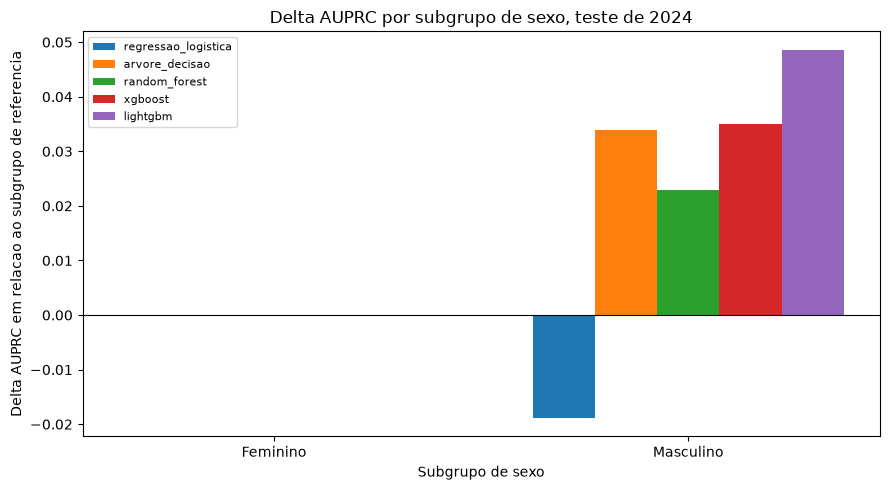

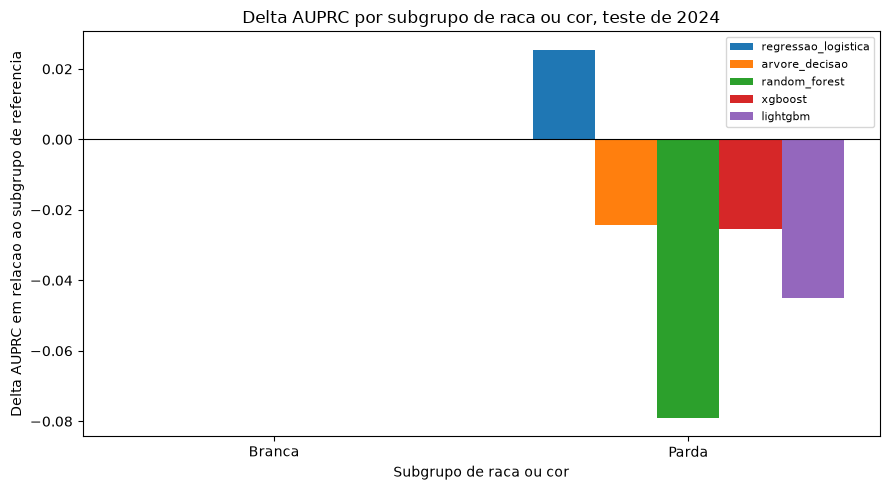

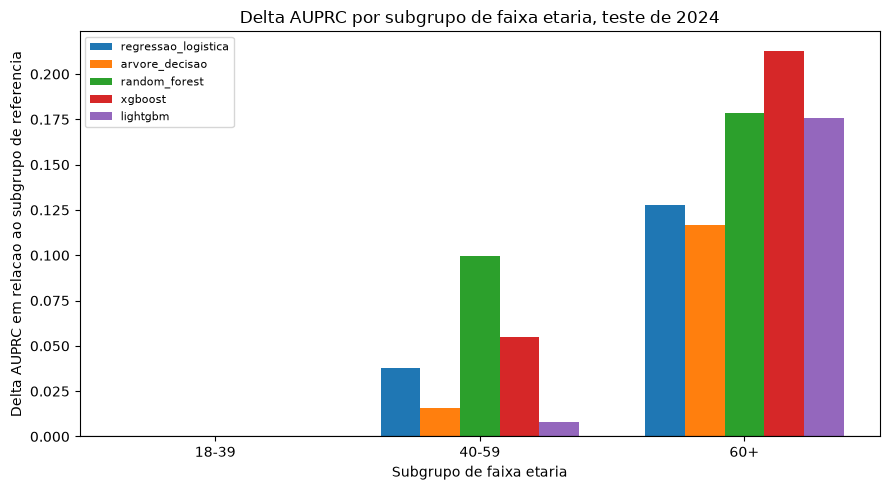

In [10]:
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    rotulo_variavel = especificacao["rotulo_variavel"]
    tabela_variavel = tabela_equidade_consolidada.loc[
        tabela_equidade_consolidada["variavel_estratificacao"] == nome_variavel
    ]
    tabela_variavel_valida = tabela_variavel.loc[
        tabela_variavel["delta_auprc"] != "amostra insuficiente"
    ].copy()
    tabela_variavel_valida["delta_auprc"] = tabela_variavel_valida["delta_auprc"].astype(float)

    ordem_subgrupos = [
        especificacao["rotulos_subgrupo"][subgrupo] for subgrupo in especificacao["subgrupos"]
    ]
    subgrupos_validos = [
        rotulo for rotulo in ordem_subgrupos if rotulo in tabela_variavel_valida["subgrupo"].unique()
    ]

    matriz_delta_auprc = tabela_variavel_valida.pivot(
        index="subgrupo", columns="algoritmo", values="delta_auprc"
    ).loc[subgrupos_validos, ALGORITMOS]

    posicoes_subgrupo = np.arange(len(subgrupos_validos))
    largura_barra = 0.15

    figura, eixo = plt.subplots(figsize=(9, 5))
    for indice_algoritmo, algoritmo in enumerate(ALGORITMOS):
        deslocamento = (indice_algoritmo - (len(ALGORITMOS) - 1) / 2) * largura_barra
        eixo.bar(
            posicoes_subgrupo + deslocamento,
            matriz_delta_auprc[algoritmo],
            width=largura_barra,
            label=algoritmo,
        )

    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.set_xticks(posicoes_subgrupo)
    eixo.set_xticklabels(subgrupos_validos)
    eixo.set_xlabel(f"Subgrupo de {rotulo_variavel}")
    eixo.set_ylabel("Delta AUPRC em relacao ao subgrupo de referencia")
    eixo.set_title(f"Delta AUPRC por subgrupo de {rotulo_variavel}, teste de 2024")
    eixo.legend(loc="best", fontsize=8)
    figura.tight_layout()
    figura.savefig(DIRETORIO_PLOTS / f"delta_auprc_{nome_variavel}.png", dpi=150)
    plt.show()

## Incerteza amostral dos deltas de equidade por bootstrap

Os deltas de AUPRC e de ROC-AUC calculados nas secoes anteriores sao estimativas pontuais, calculadas uma unica vez sobre o teste de 2024, sem nenhuma medida de incerteza associada.
Entre rodadas recentes de retreino dos cinco algoritmos, motivadas por correcoes de features nao relacionadas a equidade, a direcao de varios desses deltas mudou de sinal, o que sugere que parte deles pode ser dominada por ruido amostral em vez de refletir uma diferenca real de desempenho entre subgrupos.
Essa hipotese e particularmente relevante para raca ou cor, onde o unico subgrupo com amostra suficiente para comparacao, Parda, tem 117 obitos contra 75 da referencia Branca, e ainda mais relevante para os subgrupos ja marcados como amostra insuficiente, como Preta, com 5 obitos, e Amarela, com 2.
Esta secao estima, para cada delta calculado sobre um subgrupo com amostra suficiente, um intervalo de confianca de 95 por cento por bootstrap, com o objetivo de separar deltas estatisticamente distintos de zero de deltas que podem ser inteiramente explicados por variacao amostral.

Subgrupo e subgrupo de referencia sao populacoes disjuntas de pacientes dentro do mesmo teste de 2024, e nao a mesma populacao medida duas vezes, de forma que o bootstrap usado aqui reamostra os dois grupos de forma independente, com reposicao, em cada iteracao.
Essa escolha segue a mesma convencao de numero de reamostragens e semente aleatoria do notebook de comparacao de algoritmos da fase de avaliacao, mas usa reamostragem de duas amostras independentes em vez de reamostragem pareada, porque os subgrupos aqui comparados, diferente dos algoritmos daquele notebook, nunca compartilham os mesmos pacientes.
Uma iteracao e descartada sempre que a reamostragem do subgrupo ou a reamostragem da referencia, nessa iteracao, nao contiver as duas classes de desfecho, caso em que AUPRC e ROC-AUC deixam de ser definidos.
O subgrupo de referencia de cada variavel, Feminino, Branca e 18 a 39 anos, nao participa deste bootstrap e fica sem valor nas novas colunas de incerteza, porque compara-lo contra ele mesmo nao testa nenhuma hipotese de equidade, visto que seu delta pontual ja e zero por definicao.
A celula seguinte fixa o numero de reamostragens em 2000 e a semente aleatoria em 42, e cria o gerador de numeros aleatorios usado em todo o bootstrap desta secao.

In [11]:
NUMERO_REAMOSTRAGENS = 2000
SEMENTE_ALEATORIA = 42
gerador_aleatorio = np.random.default_rng(SEMENTE_ALEATORIA)

A celula seguinte percorre as mesmas combinacoes de variavel de estratificacao, subgrupo e algoritmo da tabela consolidada, usando as mesmas probabilidades preditas e os mesmos alvos reais ja carregados em `predicoes_com_covariaveis`.
Para cada combinacao valida, isto e, sem ser o subgrupo de referencia nem um subgrupo de amostra insuficiente, os indices do subgrupo e os indices da referencia sao reamostrados de forma independente em cada uma das 2000 iteracoes, respeitando o tamanho original de cada um dos dois grupos.
AUPRC e ROC-AUC sao recalculados sobre as duas reamostragens de cada iteracao, e a diferenca entre a metrica do subgrupo reamostrado e a da referencia reamostrada forma a distribuicao bootstrap do delta daquela combinacao.
Ao final das 2000 iteracoes, o intervalo de confianca de 95 por cento usa os percentis 2,5 e 97,5 da distribuicao de deltas, a fracao de reamostragens com delta positivo mede a direcao da evidencia, e o delta e marcado como significativo apenas quando os dois limites do intervalo tem o mesmo sinal, isto e, quando o intervalo nao contem zero.

In [12]:
linhas_bootstrap_equidade = []

for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    coluna = especificacao["coluna"]
    codigo_referencia = especificacao["subgrupo_referencia"]

    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]
        tabela_referencia = tabela_algoritmo.loc[tabela_algoritmo[coluna] == codigo_referencia]
        alvo_referencia = tabela_referencia["obito"].to_numpy()
        probabilidade_referencia = tabela_referencia["probabilidade_predita"].to_numpy()
        numero_registros_referencia = len(alvo_referencia)

        for codigo_subgrupo in especificacao["subgrupos"]:
            rotulo_subgrupo = especificacao["rotulos_subgrupo"][codigo_subgrupo]

            if codigo_subgrupo == codigo_referencia:
                continue

            tabela_subgrupo = tabela_algoritmo.loc[tabela_algoritmo[coluna] == codigo_subgrupo]
            alvo_subgrupo = tabela_subgrupo["obito"].to_numpy()
            numero_obitos_subgrupo = int(alvo_subgrupo.sum())

            if numero_obitos_subgrupo < LIMIAR_OBITOS_MINIMO:
                linhas_bootstrap_equidade.append(
                    {
                        "variavel_estratificacao": nome_variavel,
                        "subgrupo": rotulo_subgrupo,
                        "algoritmo": algoritmo,
                        "delta_auprc_ic95_inferior": "amostra insuficiente",
                        "delta_auprc_ic95_superior": "amostra insuficiente",
                        "delta_auprc_fracao_reamostragens_positivo": "amostra insuficiente",
                        "delta_auprc_significancia": "amostra insuficiente",
                        "delta_roc_auc_ic95_inferior": "amostra insuficiente",
                        "delta_roc_auc_ic95_superior": "amostra insuficiente",
                        "delta_roc_auc_fracao_reamostragens_positivo": "amostra insuficiente",
                        "delta_roc_auc_significancia": "amostra insuficiente",
                        "bootstrap_reamostragens_validas": "amostra insuficiente",
                    }
                )
                continue

            probabilidade_subgrupo = tabela_subgrupo["probabilidade_predita"].to_numpy()
            numero_registros_subgrupo = len(alvo_subgrupo)

            deltas_auprc_bootstrap = []
            deltas_roc_auc_bootstrap = []
            for _ in range(NUMERO_REAMOSTRAGENS):
                indices_subgrupo = gerador_aleatorio.integers(
                    low=0, high=numero_registros_subgrupo, size=numero_registros_subgrupo
                )
                indices_referencia = gerador_aleatorio.integers(
                    low=0, high=numero_registros_referencia, size=numero_registros_referencia
                )

                alvo_subgrupo_reamostrado = alvo_subgrupo[indices_subgrupo]
                alvo_referencia_reamostrado = alvo_referencia[indices_referencia]

                subgrupo_tem_duas_classes = 0 < alvo_subgrupo_reamostrado.sum() < numero_registros_subgrupo
                referencia_tem_duas_classes = 0 < alvo_referencia_reamostrado.sum() < numero_registros_referencia
                if not (subgrupo_tem_duas_classes and referencia_tem_duas_classes):
                    continue

                probabilidade_subgrupo_reamostrada = probabilidade_subgrupo[indices_subgrupo]
                probabilidade_referencia_reamostrada = probabilidade_referencia[indices_referencia]

                auprc_subgrupo_reamostrado = average_precision_score(
                    alvo_subgrupo_reamostrado, probabilidade_subgrupo_reamostrada
                )
                auprc_referencia_reamostrada = average_precision_score(
                    alvo_referencia_reamostrado, probabilidade_referencia_reamostrada
                )
                roc_auc_subgrupo_reamostrado = roc_auc_score(
                    alvo_subgrupo_reamostrado, probabilidade_subgrupo_reamostrada
                )
                roc_auc_referencia_reamostrada = roc_auc_score(
                    alvo_referencia_reamostrado, probabilidade_referencia_reamostrada
                )

                deltas_auprc_bootstrap.append(auprc_subgrupo_reamostrado - auprc_referencia_reamostrada)
                deltas_roc_auc_bootstrap.append(roc_auc_subgrupo_reamostrado - roc_auc_referencia_reamostrada)

            deltas_auprc_bootstrap = np.array(deltas_auprc_bootstrap)
            deltas_roc_auc_bootstrap = np.array(deltas_roc_auc_bootstrap)

            limite_inferior_auprc = np.percentile(deltas_auprc_bootstrap, 2.5)
            limite_superior_auprc = np.percentile(deltas_auprc_bootstrap, 97.5)
            fracao_positiva_auprc = (deltas_auprc_bootstrap > 0).mean()
            significancia_auprc = (
                "significativo"
                if limite_inferior_auprc * limite_superior_auprc > 0
                else "nao distinguivel de zero amostralmente"
            )

            limite_inferior_roc_auc = np.percentile(deltas_roc_auc_bootstrap, 2.5)
            limite_superior_roc_auc = np.percentile(deltas_roc_auc_bootstrap, 97.5)
            fracao_positiva_roc_auc = (deltas_roc_auc_bootstrap > 0).mean()
            significancia_roc_auc = (
                "significativo"
                if limite_inferior_roc_auc * limite_superior_roc_auc > 0
                else "nao distinguivel de zero amostralmente"
            )

            linhas_bootstrap_equidade.append(
                {
                    "variavel_estratificacao": nome_variavel,
                    "subgrupo": rotulo_subgrupo,
                    "algoritmo": algoritmo,
                    "delta_auprc_ic95_inferior": limite_inferior_auprc,
                    "delta_auprc_ic95_superior": limite_superior_auprc,
                    "delta_auprc_fracao_reamostragens_positivo": fracao_positiva_auprc,
                    "delta_auprc_significancia": significancia_auprc,
                    "delta_roc_auc_ic95_inferior": limite_inferior_roc_auc,
                    "delta_roc_auc_ic95_superior": limite_superior_roc_auc,
                    "delta_roc_auc_fracao_reamostragens_positivo": fracao_positiva_roc_auc,
                    "delta_roc_auc_significancia": significancia_roc_auc,
                    "bootstrap_reamostragens_validas": len(deltas_auprc_bootstrap),
                }
            )

tabela_bootstrap_equidade = pd.DataFrame(linhas_bootstrap_equidade)
tabela_bootstrap_equidade

,variavel_estratificacao,subgrupo,algoritmo,delta_auprc_ic95_inferior,delta_auprc_ic95_superior,delta_auprc_fracao_reamostragens_positivo,delta_auprc_significancia,delta_roc_auc_ic95_inferior,delta_roc_auc_ic95_superior,delta_roc_auc_fracao_reamostragens_positivo,delta_roc_auc_significancia,bootstrap_reamostragens_validas
0,sexo,Masculino,regressao_logistica,-0.126568,0.08053,0.371,nao distinguivel de zero amostralmente,-0.094225,0.025527,0.1325,nao distinguivel de zero amostralmente,2000
1,sexo,Masculino,arvore_decisao,-0.020797,0.079721,0.8945,nao distinguivel de zero amostralmente,-0.133988,0.028098,0.092,nao distinguivel de zero amostralmente,2000
2,sexo,Masculino,random_forest,-0.065626,0.11363,0.7065,nao distinguivel de zero amostralmente,-0.102345,0.01798,0.092,nao distinguivel de zero amostralmente,2000
3,sexo,Masculino,xgboost,-0.072964,0.129477,0.72,nao distinguivel de zero amostralmente,-0.104,0.041023,0.205,nao distinguivel de zero amostralmente,2000
4,sexo,Masculino,lightgbm,-0.039803,0.129414,0.8635,nao distinguivel de zero amostralmente,-0.08599,0.059476,0.367,nao distinguivel de zero amostralmente,2000
5,raca_cor,Preta,regressao_logistica,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
6,raca_cor,Amarela,regressao_logistica,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
7,raca_cor,Parda,regressao_logistica,-0.0824,0.123082,0.6695,nao distinguivel de zero amostralmente,-0.025268,0.098213,0.889,nao distinguivel de zero amostralmente,2000
8,raca_cor,Indigena,regressao_logistica,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
9,raca_cor,Ignorado,regressao_logistica,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente


A tabela de resultados do bootstrap e unida a tabela consolidada de metricas e deltas por subgrupo, pela combinacao de variavel de estratificacao, subgrupo e algoritmo, adicionando as novas colunas de incerteza a cada linha que ja existia.
O arquivo `tabela_equidade_consolidada.csv`, em `analysis/results_equidade/`, e sobrescrito com essa versao estendida, mantendo o mesmo nome e local do arquivo produzido na secao anterior, agora com os limites do intervalo de confianca, a fracao de reamostragens positivas e a marcacao de significancia de cada delta.

In [13]:
tabela_equidade_consolidada = tabela_equidade_consolidada.merge(
    tabela_bootstrap_equidade, on=["variavel_estratificacao", "subgrupo", "algoritmo"], how="left"
)

tabela_equidade_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "tabela_equidade_consolidada.csv", index=False
)

tabela_equidade_consolidada.sort_values(["variavel_estratificacao", "subgrupo", "algoritmo"]).reset_index(
    drop=True
)

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc,delta_auprc_ic95_inferior,delta_auprc_ic95_superior,delta_auprc_fracao_reamostragens_positivo,delta_auprc_significancia,delta_roc_auc_ic95_inferior,delta_roc_auc_ic95_superior,delta_roc_auc_fracao_reamostragens_positivo,delta_roc_auc_significancia,bootstrap_reamostragens_validas
0,faixa_etaria,1-17,arvore_decisao,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
1,faixa_etaria,1-17,lightgbm,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
2,faixa_etaria,1-17,random_forest,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
3,faixa_etaria,1-17,regressao_logistica,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
4,faixa_etaria,1-17,xgboost,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
5,faixa_etaria,18-39,arvore_decisao,927,18,0.019417,0.033318,0.676018,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,faixa_etaria,18-39,lightgbm,927,18,0.019417,0.04973,0.668561,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,faixa_etaria,18-39,random_forest,927,18,0.019417,0.045544,0.739029,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,faixa_etaria,18-39,regressao_logistica,927,18,0.019417,0.113552,0.775944,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,faixa_etaria,18-39,xgboost,927,18,0.019417,0.033711,0.591217,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Para facilitar a leitura direta dos achados que sobrevivem ao bootstrap, esta celula reorganiza a tabela estendida em formato longo, uma linha por combinacao de variavel, subgrupo, algoritmo e metrica, mantendo apenas as combinacoes marcadas como significativas.
O resultado e salvo em `analysis/results_equidade/deltas_significativos_bootstrap.csv`, e pode ficar vazio, com apenas o cabecalho das colunas, caso nenhum delta seja estatisticamente distinguivel de zero.

In [14]:
linhas_deltas_significativos = []
for _, linha in tabela_equidade_consolidada.iterrows():
    for nome_metrica, prefixo_coluna in [("auprc", "delta_auprc"), ("roc_auc", "delta_roc_auc")]:
        if linha[f"{prefixo_coluna}_significancia"] != "significativo":
            continue
        linhas_deltas_significativos.append(
            {
                "variavel_estratificacao": linha["variavel_estratificacao"],
                "subgrupo": linha["subgrupo"],
                "algoritmo": linha["algoritmo"],
                "metrica": nome_metrica,
                "delta_pontual": linha[prefixo_coluna],
                "ic95_inferior": linha[f"{prefixo_coluna}_ic95_inferior"],
                "ic95_superior": linha[f"{prefixo_coluna}_ic95_superior"],
                "fracao_reamostragens_positivo": linha[f"{prefixo_coluna}_fracao_reamostragens_positivo"],
            }
        )

colunas_deltas_significativos = [
    "variavel_estratificacao",
    "subgrupo",
    "algoritmo",
    "metrica",
    "delta_pontual",
    "ic95_inferior",
    "ic95_superior",
    "fracao_reamostragens_positivo",
]
tabela_deltas_significativos = pd.DataFrame(linhas_deltas_significativos, columns=colunas_deltas_significativos)
tabela_deltas_significativos = tabela_deltas_significativos.sort_values(
    ["variavel_estratificacao", "subgrupo", "algoritmo", "metrica"]
).reset_index(drop=True)

tabela_deltas_significativos.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "deltas_significativos_bootstrap.csv", index=False
)

tabela_deltas_significativos

,variavel_estratificacao,subgrupo,algoritmo,metrica,delta_pontual,ic95_inferior,ic95_superior,fracao_reamostragens_positivo
0,faixa_etaria,40-59,random_forest,auprc,0.099668,0.018076,0.220853,0.992
1,faixa_etaria,60+,arvore_decisao,auprc,0.116667,0.084412,0.150559,1.000
2,faixa_etaria,60+,lightgbm,auprc,0.175661,0.093725,0.243023,1.000
3,faixa_etaria,60+,random_forest,auprc,0.178393,0.105288,0.242172,1.000
4,faixa_etaria,60+,xgboost,auprc,0.212919,0.142352,0.282790,1.000


## Sintese dos achados

As secoes anteriores descreveram padroes nos deltas pontuais de AUPRC e de ROC-AUC entre subgrupos, mas nenhum deles tinha, ate aqui, nenhuma medida de incerteza amostral associada.
Das 40 combinacoes de variavel, subgrupo valido e algoritmo testadas pelo bootstrap, 20 para delta AUPRC e 20 para delta ROC-AUC, apenas 5 tem intervalo de confianca de 95 por cento que nao contem zero, e as 5 sao deltas de AUPRC da faixa etaria.
Nenhum delta de sexo, nenhum delta de raca ou cor, e nenhum delta de ROC-AUC de qualquer variavel sobrevive ao bootstrap como estatisticamente distinguivel de zero.

Para sexo, o subgrupo Masculino tem AUPRC pontual mais alta do que o Feminino em quatro dos cinco algoritmos, mas o intervalo de confianca do delta AUPRC inclui zero nos cinco, do mais estreito, entre -0,021 e 0,080 na Arvore de Decisao, ao mais largo, entre -0,127 e 0,081 na Regressao Logistica.
O delta ROC-AUC de sexo, negativo nos cinco algoritmos na estimativa pontual, entre -0,012 no LightGBM e -0,054 na Arvore de Decisao, tambem tem intervalo de confianca que inclui zero nos cinco casos, embora a fracao de reamostragens com delta negativo chegue a 90,8 por cento na Arvore de Decisao e no Random Forest, o indicio de direcao mais consistente encontrado neste notebook que, ainda assim, nao cruza o limiar de significancia de 95 por cento.

Para raca ou cor, a unica comparacao com amostra suficiente nos cinco algoritmos continua sendo Parda contra Branca, e nenhum dos dez deltas, cinco de AUPRC e cinco de ROC-AUC, tem intervalo de confianca fora de zero.
O caso mais proximo do limiar de significancia e o delta AUPRC do Random Forest, -0,079 na estimativa pontual, com intervalo de confianca entre -0,198 e 0,009 e apenas 3,7 por cento das reamostragens com delta positivo, o que aponta na mesma direcao da estimativa pontual sem excluir a hipotese de delta zero.
As categorias Preta, Amarela, Indigena e Ignorado continuam abaixo do limiar de 10 obitos usado neste notebook, e o bootstrap nao resolve essa limitacao, porque nenhuma tecnica de reamostragem cria informacao que nao esta presente na amostra original.

Faixa etaria e a unica variavel com deltas que sobrevivem ao bootstrap, e apenas para AUPRC, nunca para ROC-AUC.
O delta AUPRC da faixa de 60 anos ou mais em relacao a de 18 a 39 anos tem intervalo de confianca inteiramente positivo em quatro dos cinco algoritmos, entre 0,084 e 0,151 na Arvore de Decisao, entre 0,105 e 0,242 no Random Forest, entre 0,142 e 0,283 no XGBoost, e entre 0,094 e 0,243 no LightGBM, com 100 por cento das reamostragens positivas nos quatro.
Na Regressao Logistica, o unico dos cinco algoritmos em que esse delta nao e significativo, a estimativa pontual, 0,128, fica dentro da faixa dos outros quatro algoritmos, mas o intervalo de confianca, entre -0,047 e 0,232, e varias vezes mais largo, o que reflete maior variancia da AUPRC sob reamostragem nesse algoritmo especificamente, e nao uma estimativa pontual discrepante.
O delta AUPRC da faixa de 40 a 59 anos em relacao a de 18 a 39 anos e significativo apenas no Random Forest, entre 0,018 e 0,221, com 99,2 por cento das reamostragens positivas, enquanto o XGBoost chega perto do limiar, com intervalo entre -0,004 e 0,161 e 96,9 por cento das reamostragens positivas, sem o limite inferior cruzar para o lado positivo.
Para nenhuma das duas faixas, 40 a 59 ou 60 anos ou mais, o delta ROC-AUC tem intervalo de confianca fora de zero em qualquer dos cinco algoritmos, o que confirma, agora com uma medida de incerteza explicita, a inconsistencia de sinal entre algoritmos ja visivel nas estimativas pontuais da secao anterior.

Em conjunto, o bootstrap indica que a capacidade de discriminacao de risco, medida pelo ROC-AUC, nao tem nenhuma diferenca estatisticamente distinguivel de zero entre subgrupos em nenhuma das tres variaveis de estratificacao, com os dados e os modelos atuais.
O unico achado que sobrevive e uma AUPRC mais alta no subgrupo de 60 anos ou mais do que no de 18 a 39 anos, presente em quatro dos cinco algoritmos, e esse achado e compativel com a maior prevalencia observada de obito nessa faixa etaria, 11,9 por cento contra 1,9 por cento, ja que a AUPRC tem a prevalencia da classe positiva como piso.
Esse achado de AUPRC nao implica, por si so, uma diferenca real na capacidade do modelo de ordenar o risco dentro de cada subgrupo, uma distincao que o ROC-AUC, sem intervalo de confianca significativo em nenhum algoritmo para essa mesma comparacao, nao permite confirmar.
Os padroes de sexo e de raca ou cor, incluindo o sinal consistente de ROC-AUC mais baixo no subgrupo Masculino observado nos cinco algoritmos nas estimativas pontuais, nao sobrevivem ao bootstrap como estatisticamente distinguiveis de zero, e devem ser tratados, com os dados atuais, como ruido amostral e nao como evidencia de uma diferenca real de equidade entre esses subgrupos.
Essa conclusao e consistente com a mudanca de sinal observada entre rodadas de retreino recentes do modelo, inclusive na propria faixa etaria de 60 anos ou mais no eixo do ROC-AUC, e reforca a necessidade de reportar, daqui em diante, o intervalo de confianca ao lado de qualquer delta de equidade, em vez de apenas a estimativa pontual.